In [57]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns


df = pd.read_csv("player_summary.csv")

In [58]:
df.head()

df=df.drop(columns = "bat_runs_above_avg")

In [59]:
df.head()

,player,phase,matches,bat_innings,bat_balls,bat_runs,bat_outs,bat_avg,bat_sr,bat_4s,bat_6s,bowl_balls,bowl_wkts,bowl_avg,bowl_runs,bowl_economy,bowl_4fers,bowl_5fers
0,A Adey,Mid,1,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,18.0,1.0,34.0,34.0,11.33,0.0,0.0
1,A Balbirnie,Opening,42,42.0,524.0,768.0,17.0,45.18,146.56,102.0,23.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
2,A Balbirnie,Mid,24,24.0,331.0,485.0,18.0,26.94,146.53,53.0,15.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
3,A Balbirnie,Death,4,4.0,25.0,61.0,2.0,30.50,244.00,3.0,6.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
4,A Cawley,Opening,10,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,114.0,4.0,32.0,128.0,6.74,0.0,0.0


                                 STASTISTICAL DESCRIPTION AND PATTERN ANALYSIS 

In [60]:
# Desciptive Statistics 

numeric_df = df.select_dtypes(include = np.number)

stats = numeric_df.describe().T

stats = stats[['count' , 'mean' , '50%' , 'std' , 'min' , 'max']]

stats = stats.rename(columns= {"50%": "median"})

print(stats.round(2))

              count    mean  median     std   min     max
matches       532.0    8.01    4.00    9.14  1.00   49.00
bat_innings   532.0    4.74    2.00    6.87  0.00   49.00
bat_balls     532.0   43.27   14.00   76.18  0.00  577.00
bat_runs      532.0   56.27   13.00  106.95  0.00  768.00
bat_outs      532.0    2.63    1.00    4.01  0.00   26.00
bat_avg       345.0   17.57   14.00   15.56  0.00  108.00
bat_sr        425.0  107.71  105.56   53.59  0.00  273.68
bat_4s        532.0    5.14    1.00   10.94  0.00  102.00
bat_6s        532.0    2.45    0.00    5.09  0.00   35.00
bowl_balls    532.0   43.27   12.00   82.20  0.00  644.00
bowl_wkts     532.0    2.55    0.00    4.96  0.00   36.00
bowl_avg      245.0   24.59   20.69   15.88  1.67  107.00
bowl_runs     532.0   58.92   15.00  107.26  0.00  745.00
bowl_economy  330.0    8.96    8.22    3.63  2.00   33.00
bowl_4fers    532.0    0.01    0.00    0.07  0.00    1.00
bowl_5fers    532.0    0.01    0.00    0.11  0.00    2.00


In [61]:
# Phase wise statistical analysis 

phase_stats = df.groupby('phase')[
    ['bat_runs', 'bat_avg', 'bat_sr',
     'bowl_wkts', 'bowl_avg', 'bowl_economy']
].agg(['mean', 'median', 'std'])

print(phase_stats)

          bat_runs                       bat_avg                    \
              mean median         std       mean median        std   
phase                                                                
Death    36.723529   16.0   53.357675  14.639308   9.80  14.344526   
Mid      71.155440   18.0  122.263448  17.136154  15.25  12.137926   
Opening  58.923077    7.0  124.720879  22.731412  16.33  20.229853   

             bat_sr                     bowl_wkts                    bowl_avg  \
               mean   median        std      mean median       std       mean   
phase                                                                           
Death    116.551731  111.805  62.698919  2.100000    0.0  3.741104  19.041250   
Mid      101.294691  100.000  46.055819  3.176166    1.0  6.113514  26.136020   
Opening  104.527944  106.250  48.257598  2.301775    0.0  4.514269  27.905867   

                          bowl_economy                   
        median        std         

In [62]:
# Pattern Analysis 
# Player performance changes across the different phases Opening , Middle and Depth Phase 

# A. Batting Performance across the phases 

batting_pattern = df.groupby('phase').agg(
    total_runs = ('bat_runs' , 'sum'),
    avg_runs = ('bat_runs' , 'mean'),
    avg_batting_average = ('bat_avg' , 'mean'),
    avg_strike_rate = ('bat_sr' , 'mean'),
    total_fours = ('bat_4s' , 'sum'),
    total_Six = ('bat_6s' , 'sum')
)

print(batting_pattern.round(2))

         total_runs  avg_runs  avg_batting_average  avg_strike_rate  \
phase                                                                 
Death        6243.0     36.72                14.64           116.55   
Mid         13733.0     71.16                17.14           101.29   
Opening      9958.0     58.92                22.73           104.53   

         total_fours  total_Six  
phase                            
Death          486.0      323.0  
Mid           1051.0      611.0  
Opening       1197.0      372.0  


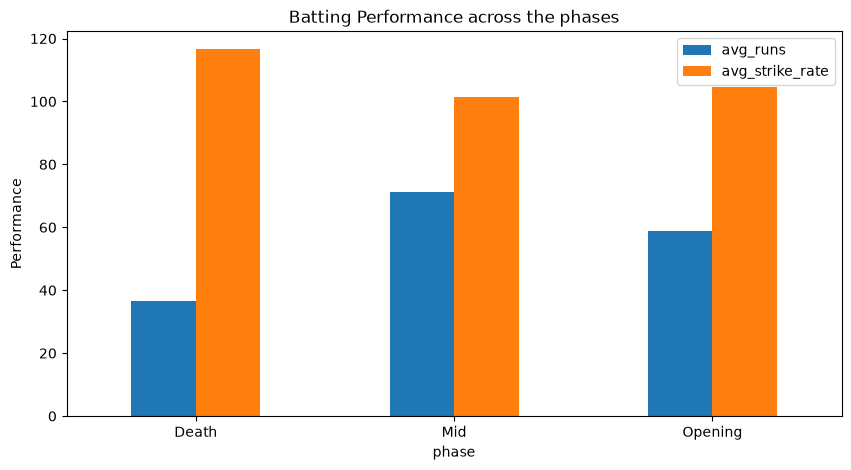

In [63]:
# Visualization of batting performance 

batting_pattern[['avg_runs' , 'avg_strike_rate']].plot(kind = 'bar' , figsize=(10,5))

plt.title("Batting Performance across the phases")
plt.ylabel("Performance")
plt.xticks(rotation=0)
plt.show()

In [64]:
# B. Bowling Performance across the phases 

bowling_pattern = df.groupby('phase').agg(
    total_wickets = ('bowl_wkts' , 'sum'),
    average_wicket = ('bowl_wkts' , 'mean'),
    avg_bowling_average = ('bowl_avg', 'mean'),
    avg_economy = ('bowl_economy' , 'mean')
)

print(bowling_pattern.round(2))

         total_wickets  average_wicket  avg_bowling_average  avg_economy
phase                                                                   
Death            357.0            2.10                19.04         9.78
Mid              613.0            3.18                26.14         8.54
Opening          389.0            2.30                27.91         8.69


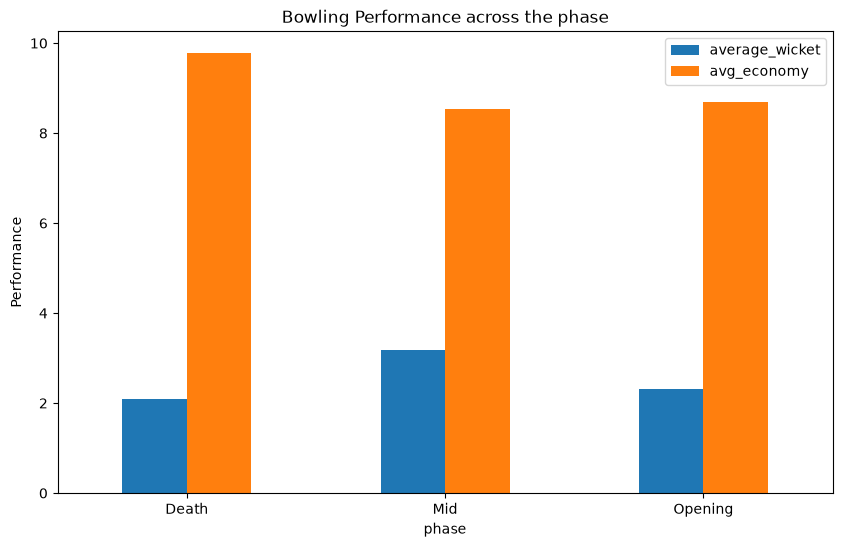

In [65]:
# Visualization of Bowling performance 

bowling_pattern[['average_wicket' , 'avg_economy']].plot(kind = "bar" , figsize=(10,6))

plt.title("Bowling Performance across the phase")
plt.ylabel("Performance")
plt.xticks(rotation=0)
plt.show()

In [66]:
# C. Identify Player specific patterns 

top_batters = df[df['bat_balls'] >= 43.27 ].sort_values(['phase' , 'bat_sr'], ascending = [True, False])

for phase in df['phase'].unique():

    print(f"\n Top Batters - {phase}")

    print(
        top_batters[top_batters['phase'] == phase][['player' , 'bat_runs' , 'bat_avg' , 'bat_sr']].head(10)
    )


 Top Batters - Mid
          player  bat_runs  bat_avg  bat_sr
269   KJ O'Brien     217.0    31.00  200.93
173     GR Adair     262.0    32.75  196.99
64     C Campher     214.0    30.57  167.19
33      AR Frost     133.0    33.25  162.20
276     L Tucker     725.0    31.52  160.40
254  JNK Shannon      76.0    38.00  158.33
319    M Topping     295.0    36.88  157.75
294    M Commins     215.0    30.71  152.48
477    ST Doheny     479.0    26.61  148.30
510    TH Tector     523.0    40.23  148.16

 Top Batters - Opening
           player  bat_runs  bat_avg  bat_sr
342      MR Adair      84.0    28.00  171.43
304        M Ford     108.0   108.00  166.15
509     TH Tector     603.0    43.07  159.95
172      GR Adair     417.0    20.85  157.36
396   PR Stirling     460.0    27.06  156.46
160     GJ Delany     336.0    33.60  154.84
69   C De Freitas     239.0    59.75  151.27
318     M Topping     181.0    22.62  148.36
482    Simi Singh     361.0    40.11  147.35
1     A Balbirnie     

In [67]:
# Unsual values and Outlier analysis 

features = [    'bat_runs',
    'bat_avg',
    'bat_sr',
    'bowl_wkts',
    'bowl_avg',
    'bowl_economy']

for col in features: 
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1 
    lower = Q1 - 1.5 * IQR
    higher = Q3 + 1.5 * IQR 

    outliers = df[(df[col] > lower) | (df[col] < higher)]

    print(f"Feature : {col}")
    print(f"Lower bound" ,lower)
    print(f"Higher bound" , higher)
    print(f"Outlier count " ,  len(outliers))


Feature : bat_runs
Lower bound -85.25
Higher bound 144.75
Outlier count  532
Feature : bat_avg
Lower bound -20.5
Higher bound 51.5
Outlier count  345
Feature : bat_sr
Lower bound -28.445000000000007
Higher bound 242.955
Outlier count  425
Feature : bowl_wkts
Lower bound -4.5
Higher bound 7.5
Outlier count  532
Feature : bowl_avg
Lower bound -7.5
Higher bound 52.5
Outlier count  245
Feature : bowl_economy
Lower bound 2.5299999999999994
Higher bound 14.450000000000001
Outlier count  330


In [68]:
col = 'bat_sr'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR

unusual_players = df[df[col] > upper]

print(
    unusual_players[
        ['player', 'phase', 'bat_balls', 'bat_runs', 'bat_sr']
    ]
)

          player    phase  bat_balls  bat_runs  bat_sr
3    A Balbirnie    Death       25.0      61.0  244.00
162    GJ Delany    Death       52.0     136.0  261.54
389      PJ Moor    Death       12.0      32.0  266.67
437   S Dadswell  Opening        5.0      13.0  260.00
478    ST Doheny    Death       38.0     104.0  273.68


                                                DESCRIPTION OF PHASE 2 
